Lab Sheet 03 - Developing a tiny transformer model

## Load the dataset ##

In [ ]:
#Install and Import libraries
!pip -q install datasets
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset

torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


In [ ]:
#Load the TinyStories dataset

dataset = load_dataset(
    "roneneldan/TinyStories",
    split="train[:1000]"
)

dataset = dataset.train_test_split(
    test_size=0.1,
    seed=42
)

train_text = "\n".join(dataset["train"]["text"])
val_text = "\n".join(dataset["test"]["text"])

print("Training stories:", len(dataset["train"]))
print("Validation stories:", len(dataset["test"]))
print(train_text[:500])

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

data/train-00002-of-00004-a26307300439e9(…): reconstructing file:   0%|          |  0.00B /  246MB            

... (4 outputs left out)

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Training stories: 900
Validation stories: 100
Anna and Ben are friends. They like to play together. Today, they have a task. They have to find a beautiful flower for their teacher.

They walk in the park. They see many flowers. Some are red, some are yellow, some are pink. But they want to find the most beautiful flower of all.

They see a big hill. They think maybe there is a beautiful flower on top of the hill. They run to the hill. They jump over rocks and sticks. They climb up the hill. They are tired, but they are happy.

They reach th


## Preprocess the text ##

In [ ]:
#Convert text into numerical IDs
chars = sorted(set(train_text + val_text))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

def encode(text):
    return [stoi[ch] for ch in text]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

train_data = torch.tensor(
    encode(train_text), dtype=torch.long
)

val_data = torch.tensor(
    encode(val_text), dtype=torch.long
)

print("Vocabulary size:", vocab_size)
print("Encoded sample:", encode("Once upon a time")[:10])
print("Decoded sample:", decode(encode("Once upon a time")))

Vocabulary size: 75
Encoded sample: [31, 56, 45, 47, 1, 63, 58, 57, 56, 1]
Decoded sample: Once upon a time


## Build the Transformer Architecture ##

In [ ]:
# Define the tiny Transformer

class TinyTransformer(nn.Module):
    def __init__(self):
        super().__init__()

        self.token_emb = nn.Embedding(vocab_size, 64)
        self.pos_emb = nn.Embedding(64, 64)

        layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=2,
            dim_feedforward=128,
            dropout=0.0,
            batch_first=True,
            activation="gelu"
        )

        self.blocks = nn.TransformerEncoder(
            layer,
            num_layers=2
        )

        self.lm_head = nn.Linear(64, vocab_size)

    def forward(self, idx):
        B, T = idx.shape

        positions = torch.arange(T, device=idx.device)

        x = self.token_emb(idx) + self.pos_emb(positions)

        # Prevent each position from seeing future characters
        mask = torch.triu(
            torch.ones(
                T, T,
                device=idx.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        x = self.blocks(x, mask=mask)

        return self.lm_head(x)


model = TinyTransformer().to(device)

print(
    "Number of parameters:",
    sum(p.numel() for p in model.parameters())
)

Number of parameters: 80715


## Preparing training data ##

In [ ]:
# Prepare input and target sequences

block_size = 64
batch_size = 32

def get_batch(split_name):
    source = train_data if split_name == "train" else val_data

    starts = torch.randint(
        len(source) - block_size - 1,
        (batch_size,)
    )

    x = torch.stack([
        source[i:i + block_size] for i in starts
    ])

    y = torch.stack([
        source[i + 1:i + block_size + 1] for i in starts
    ])

    return x.to(device), y.to(device)


x, y = get_batch("train")

print("Input shape:", x.shape)
print("Target shape:", y.shape)

Input shape: torch.Size([32, 64])
Target shape: torch.Size([32, 64])


 ## Initialize and Train the model ##


In [ ]:
# Train the Transformer

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001
)

train_history = []
val_history = []

@torch.no_grad()
def evaluate(split_name, num_batches=10):
    model.eval()
    losses = []

    for _ in range(num_batches):
        x, y = get_batch(split_name)
        logits = model(x)

        loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        losses.append(loss.item())

    model.train()
    return sum(losses) / len(losses)


for epoch in range(15):
    model.train()
    total_loss = 0.0

    for step in range(100):
        x, y = get_batch("train")

        logits = model(x)

        loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    train_loss = total_loss / 100
    val_loss = evaluate("val", num_batches=10)

    train_history.append(train_loss)
    val_history.append(val_loss)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train loss: {train_loss:.3f} | "
        f"Validation loss: {val_loss:.3f}"
    )

Epoch 01 | Train loss: 2.888 | Validation loss: 2.526
Epoch 02 | Train loss: 2.416 | Validation loss: 2.354
Epoch 03 | Train loss: 2.306 | Validation loss: 2.252
Epoch 04 | Train loss: 2.202 | Validation loss: 2.150
Epoch 05 | Train loss: 2.090 | Validation loss: 2.058
Epoch 06 | Train loss: 1.993 | Validation loss: 1.937
Epoch 07 | Train loss: 1.905 | Validation loss: 1.855
Epoch 08 | Train loss: 1.836 | Validation loss: 1.813
Epoch 09 | Train loss: 1.777 | Validation loss: 1.750
Epoch 10 | Train loss: 1.734 | Validation loss: 1.702
Epoch 11 | Train loss: 1.695 | Validation loss: 1.685
Epoch 12 | Train loss: 1.658 | Validation loss: 1.660
Epoch 13 | Train loss: 1.632 | Validation loss: 1.627
Epoch 14 | Train loss: 1.606 | Validation loss: 1.624
Epoch 15 | Train loss: 1.585 | Validation loss: 1.563


## Monitor training ##

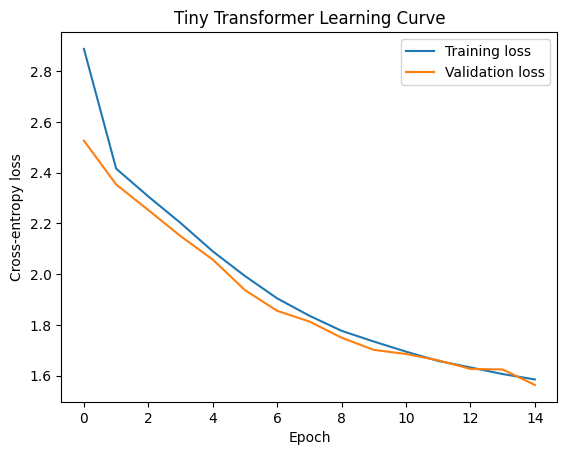

In [ ]:
# Plot the training and validation losses"""

import matplotlib.pyplot as plt

plt.plot(train_history, label="Training loss")
plt.plot(val_history, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Tiny Transformer Learning Curve")
plt.legend()
plt.show()

## Evaluate the model ##

In [ ]:
# Calculate validation perplexity

val_loss = evaluate("val", num_batches=20)
val_perplexity = math.exp(min(val_loss, 20))

print(f"Validation loss: {val_loss:.4f}")
print(f"Validation perplexity: {val_perplexity:.2f}")

Validation loss: 1.5990
Validation perplexity: 4.95


## Generate stories ##

In [ ]:
!pip -q install gradio

In [ ]:
# Step 9 - Generate stories using the trained Transformer

@torch.no_grad()
def generate(prompt, max_new_chars=200):
    model.eval()

    # Convert prompt into numerical IDs
    input_ids = torch.tensor(
        [encode(prompt)],
        dtype=torch.long,
        device=device
    )

    for _ in range(max_new_chars):

        # Use only the last 64 characters
        idx_cond = input_ids[:, -block_size:]

        # Predict the next character
        logits = model(idx_cond)

        # Select predictions for the last position
        logits = logits[:, -1, :]

        # Convert predictions into probabilities
        probs = F.softmax(logits, dim=-1)

        # Sample the next character
        next_token = torch.multinomial(
            probs,
            num_samples=1
        )

        # Add the new character to the sequence
        input_ids = torch.cat(
            (input_ids, next_token),
            dim=1
        )

    # Convert numerical IDs back into text
    return decode(input_ids[0].tolist())

print("Text generation function created successfully!")

Text generation function created successfully!


In [ ]:
# Generate a story

prompt = "Once upon a time"

generated_story = generate(
    prompt,
    max_new_chars=300
)

print("Starting Prompt:", prompt)
print("\nGenerated Story:\n")
print(generated_story)

Starting Prompt: Once upon a time

Generated Story:

Once upon a time. They disten said. Thell were chaned thinnd Say upones opled some beack. Appar enomed in town a loved. Lily she waven tulnes fran too the so hupe rep the have suice were a did battle was batch. She the you, see big noilzy, liking in the wanted to he ring jidepoinmined was as groad higpad to even ev


In [ ]:
#Built basic chat with the model traine
import gradio as gr
def chat_with_transformer(message, history):
    if not message or not message.strip():
        return "Please enter a message."

    if "stoi" not in globals() or "generate" not in globals():
        return "Error: Please run the cells that define stoi and generate first."

    supported = "".join(ch for ch in message if ch in stoi)

    if not supported:
        return "Please try text using characters in the training dataset."

    try:
        return generate(supported, max_new_chars=100)
    except Exception as e:
        return f"Text generation failed: {type(e).__name__}: {e}"

demo = gr.ChatInterface(
    fn=chat_with_transformer,
    title="My Tiny Transformer Chatbot",
    description="A language model trained from scratch in our LLM class."
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ed5751fd3dbb189e77.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


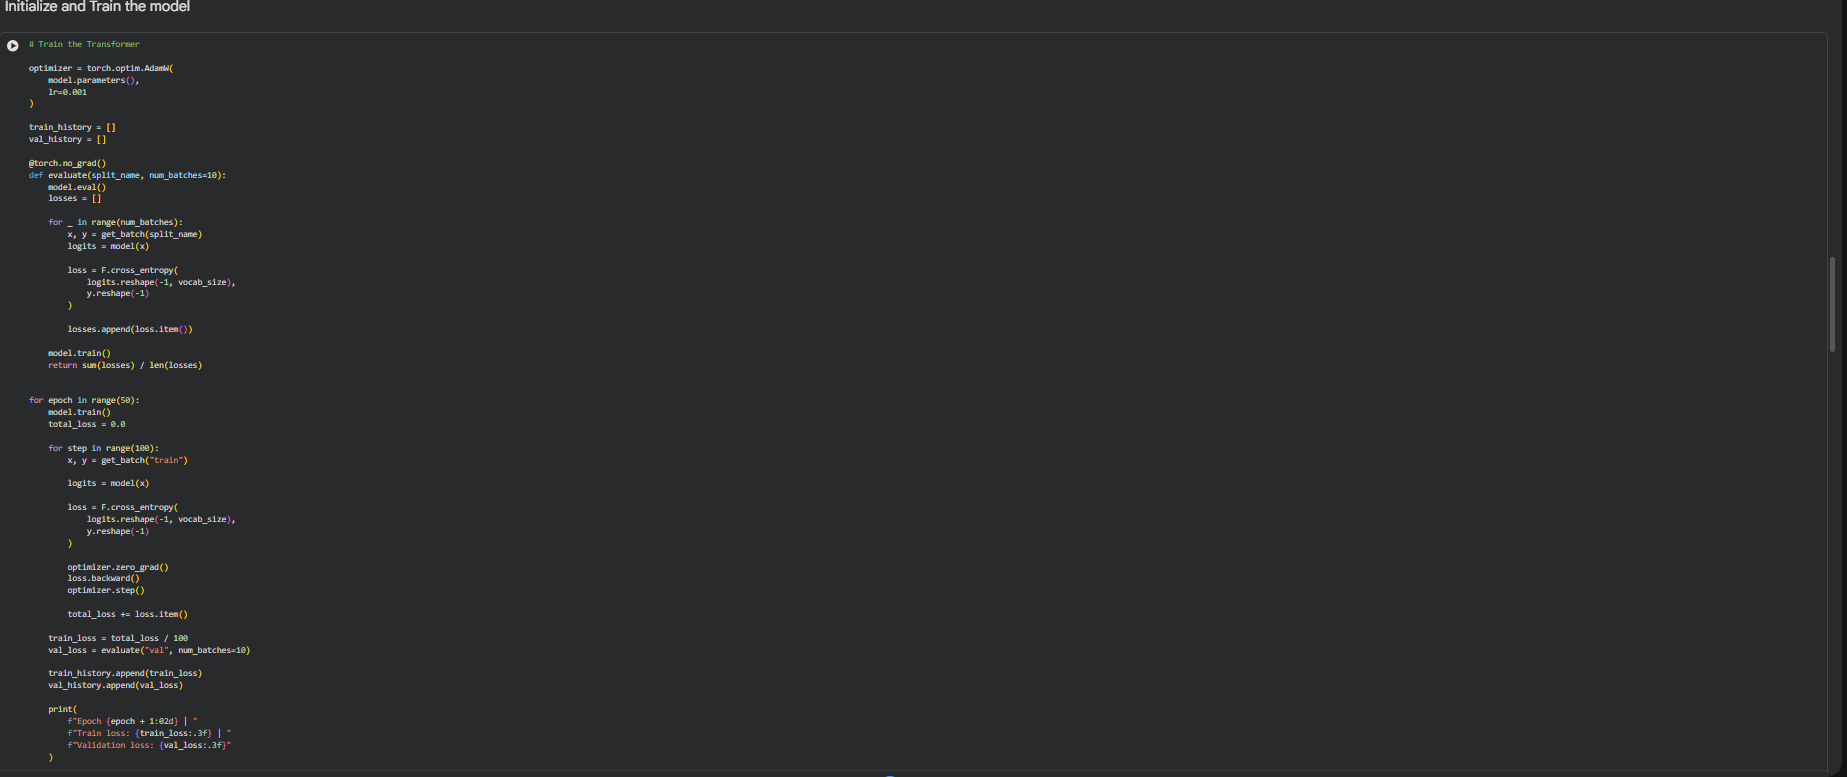

# 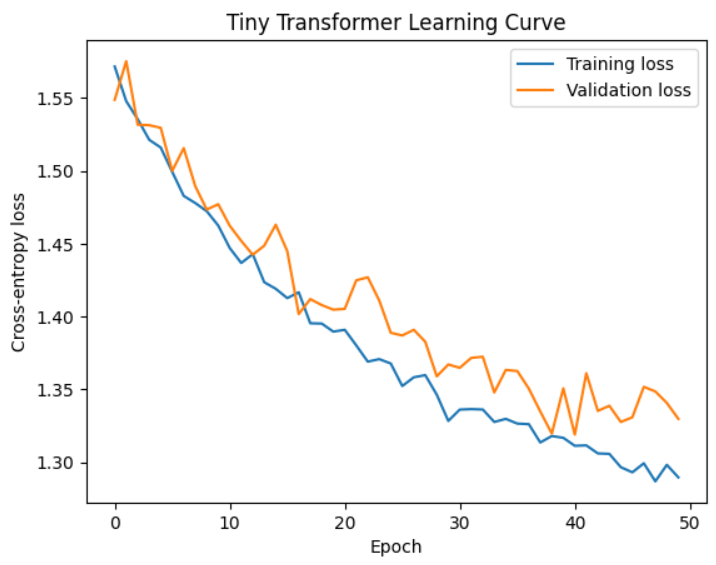

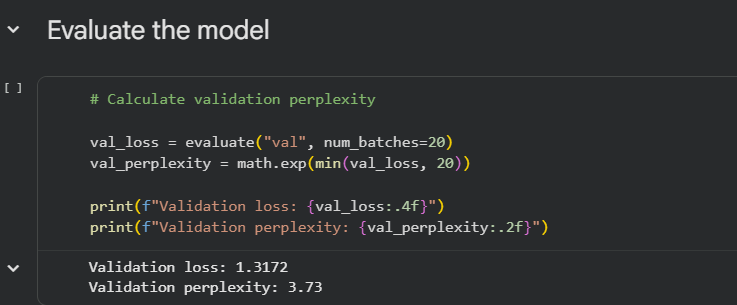


The Tiny Transformer model was trained using 15 and 50 epochs to compare its performance.

When trained for 15 epochs, the model achieved a validation loss of 1.5990 and a validation perplexity of 4.95. After increasing the training to 50 epochs, the validation loss decreased to 1.3172, and the validation perplexity decreased to 3.73.

The learning curves show that both training and validation losses decreased as the number of epochs increased. However the validation loss fluctuated slightly during later epochs.

Increasing the number of epochs from 15 to 50 improved the model's performance by reducing validation loss and perplexity. This indicates that the model learned the training patterns more effectively, although the generated text quality would need to be compared separately.

## Save the trained model ##


In [ ]:
# Save the trained model

checkpoint = {
    "model_state_dict": model.state_dict(),
    "chars": chars,
    "vocab_size": vocab_size,
    "config": {
        "embedding_dim": 64,
        "num_heads": 2,
        "num_layers": 2,
        "block_size": 64,
        "feedforward_dim": 128
    }
}

torch.save(checkpoint, "tiny_transformer.pt")

print("Model saved successfully!")

from google.colab import files

files.download("tiny_transformer.pt")

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Objectives

1. To understand the basic architecture and working principles of a Transformer model.
2. To preprocess text data and prepare it for model training.
3. To build and train a Tiny Transformer model using PyTorch.
4. To evaluate model performance using training loss, validation loss, and perplexity.
5. To generate text using the trained model and compare performance across different training epochs.

## Learning Outcomes

1. Gained an understanding of Transformer architecture and its application in text generation.
2. Learned how to preprocess text data and prepare training sequences.
3. Developed practical skills in implementing and training a Transformer model using PyTorch.
4. Learned to monitor and evaluate model performance using learning curves and perplexity.
5. Understood how changing the number of training epochs affects model performance and the risk of overfitting.
6. Gained experience in generating text using a trained Transformer model.